# Analyse exploratoire et tests statistiques préalables

Mémoire M2 EGRF - Détection et pilotage du risque opérationnel bancaire

Ce notebook part de la base nettoyée (`pcold_clean.csv`) et couvre deux volets :
- **a) Analyse descriptive** : distribution du montant des pertes, répartition des événements par catégorie bâloise dans le temps
- **b) Analyse de stationnarité** : tests ADF sur les séries de fréquence et de sévérité, et vérification d'un éventuel effet de troncature en fin de période

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller

plt.rcParams['figure.figsize'] = (10, 5)

In [7]:
df = pd.read_csv(
    r"D:\Université De Rouen\Mémoire_HAMED_ROUEN\Base\pcold_clean.csv",
    sep=";"
)

print(df.head())
print(f"{len(df)} événements chargés.")
df.head()

   Event ID Occurrence year Occurrence month End year End month  \
0         1            1999                8     2000        11   
1         2            1998               12     2000        11   
2         3            1997                7     2000         4   
3         4            2000                2        F         F   
4         5            1995                2     2000         9   

   Loss amount (Unit: 10,000 CNY) Bank involved code Province occurred  \
0                         10200.0           5,6,7,42           Shaanxi   
1                           420.0                  4         Guangdong   
2                           332.0                  4         Guangdong   
3                          2102.0                  4           Tianjin   
4                          1580.0                  4           Beijing   

  City occurred Causal factor  ... banque_principale banque_toutes  \
0         Xi'an        People  ...               5.0      5,6,7,42   
1      Dongg

,Event ID,Occurrence year,Occurrence month,End year,End month,"Loss amount (Unit: 10,000 CNY)",Bank involved code,Province occurred,City occurred,Causal factor,...,banque_principale,banque_toutes,banque_multiple,province_principale,province_toutes,province_multiple,ville_principale,ville_toutes,ville_multiple,type_evenement
0,1,1999,8,2000,11,10200.0,"5,6,7,42",Shaanxi,Xi'an,People,...,5.0,"5,6,7,42",True,Shaanxi,Shaanxi,False,Xi'an,Xi'an,False,Internal fraud
1,2,1998,12,2000,11,420.0,4,Guangdong,Dongguan,People,...,4.0,4,False,Guangdong,Guangdong,False,Dongguan,Dongguan,False,Internal fraud
2,3,1997,7,2000,4,332.0,4,Guangdong,Shenzhen,People,...,4.0,4,False,Guangdong,Guangdong,False,Shenzhen,Shenzhen,False,Internal fraud
3,4,2000,2,F,F,2102.0,4,Tianjin,F,People,...,4.0,4,False,Tianjin,Tianjin,False,NaN,F,False,Internal fraud
4,5,1995,2,2000,9,1580.0,4,Beijing,Beijing,People,...,4.0,4,False,Beijing,Beijing,False,Beijing,Beijing,False,Internal fraud


## a) Analyse descriptive

### Distribution du montant des pertes

On compare la distribution brute (en 10 000 CNY) et sa transformation logarithmique, pour illustrer pourquoi `log_loss` est nécessaire à la modélisation de la sévérité.

In [14]:
loss = df['Loss amount (Unit: 10,000 CNY)']
logloss = df['log_loss']

stats_loss = pd.DataFrame({
    'Loss amount (brut)': [loss.min(), loss.mean(), loss.median(), loss.max(), loss.std(),
                            stats.skew(loss), stats.kurtosis(loss)],
    'log_loss': [logloss.min(), logloss.mean(), logloss.median(), logloss.max(), logloss.std(),
                 stats.skew(logloss), stats.kurtosis(logloss)]
}, index=['Minimum','Moyenne', 'Médiane', 'Maximum','Écart-type', 'Skewness', 'Kurtosis'])

stats_loss.round(2)

,Loss amount (brut),log_loss
Minimum,0.00,-12.21
Moyenne,28490.58,4.93
Médiane,70.00,4.25
Maximum,41000000.00,17.53
Écart-type,704236.20,3.17
Skewness,53.81,0.33
Kurtosis,3087.41,0.13


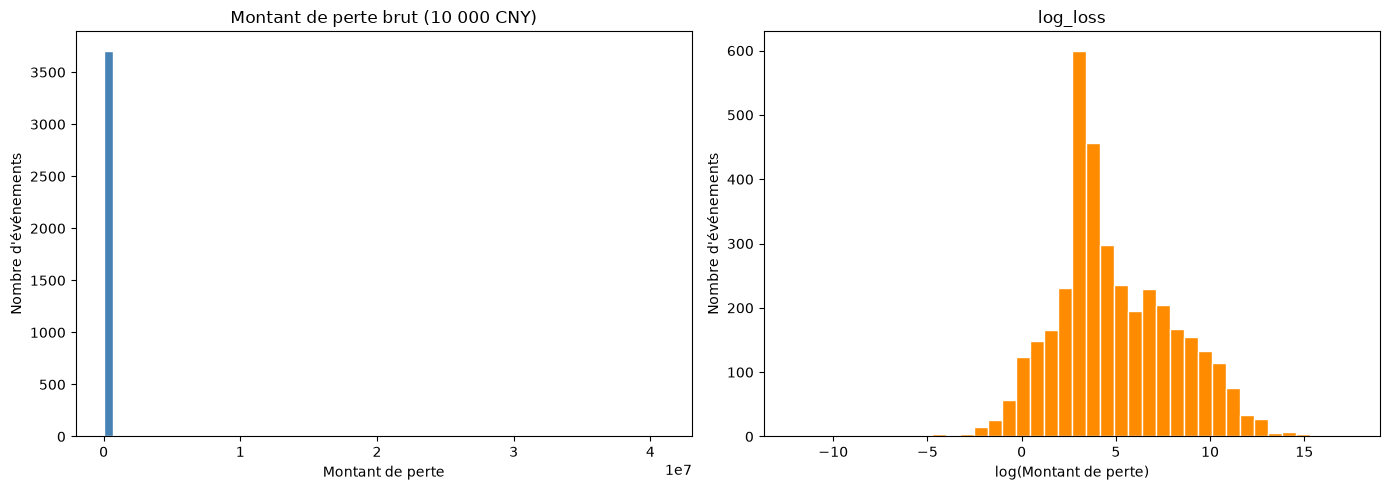

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(loss, bins=60, color='steelblue', edgecolor='white')
axes[0].set_title("Montant de perte brut (10 000 CNY)")
axes[0].set_xlabel("Montant de perte")
axes[0].set_ylabel("Nombre d'événements")

axes[1].hist(logloss, bins=40, color='darkorange', edgecolor='white')
axes[1].set_title("log_loss")
axes[1].set_xlabel("log(Montant de perte)")
axes[1].set_ylabel("Nombre d'événements")

plt.tight_layout()
plt.show()

La distribution brute est extrêmement asymétrique (skewness très élevé, quelques pertes exceptionnelles écrasant l'échelle), tandis que `log_loss` s'approche d'une distribution quasi symétrique, plus adaptée à la modélisation.

### Répartition des événements par catégorie bâloise dans le temps

In [23]:
df_temps = df.copy()
df_temps['Occurrence year'] = pd.to_numeric(df_temps['Occurrence year'], errors='coerce')
df_temps = df_temps.dropna(subset=['Occurrence year'])
df_temps['Occurrence year'] = df_temps['Occurrence year'].astype(int)

table_annee_type = pd.crosstab(df_temps['Occurrence year'], df_temps['type_evenement'])
table_annee_type.tail(10)

type_evenement,Autres,"Clients, products & business practices","Execution, delivery & process management",External fraud,Internal fraud
Occurrence year,,,,,
2013,1,7,6,58,77
2014,2,9,7,49,61
2015,2,21,7,44,60
2016,3,17,22,52,48
2017,12,146,104,18,77
2018,5,151,152,13,84
2019,2,119,182,13,58
2020,0,4,6,2,4
2021,0,0,1,6,1


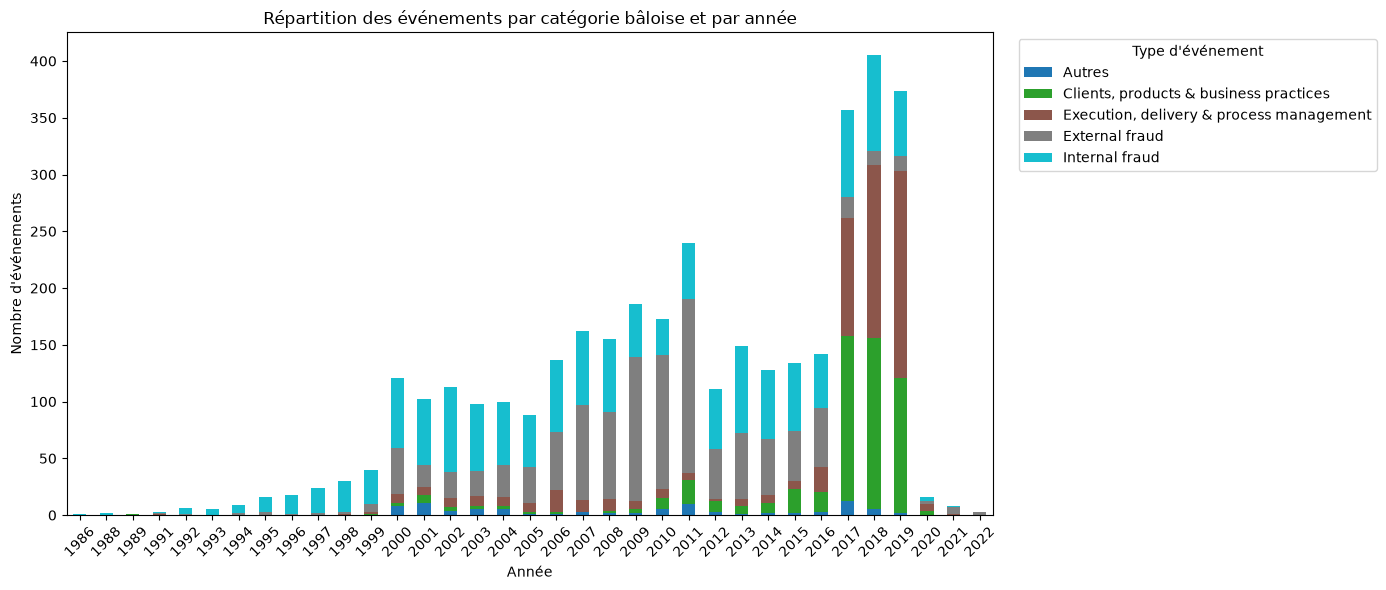

In [24]:
table_annee_type.plot(kind='bar', stacked=True, figsize=(14, 6), colormap='tab10')
plt.title("Répartition des événements par catégorie bâloise et par année")
plt.xlabel("Année")
plt.ylabel("Nombre d'événements")
plt.xticks(rotation=45)
plt.legend(title="Type d'événement", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## b) Analyse de stationnarité et tests statistiques

La base couvre plus de trente ans. On teste la stationnarité de la série de fréquence annuelle et de la série de sévérité annuelle moyenne (en log) à l'aide du test de Dickey-Fuller augmenté (ADF).

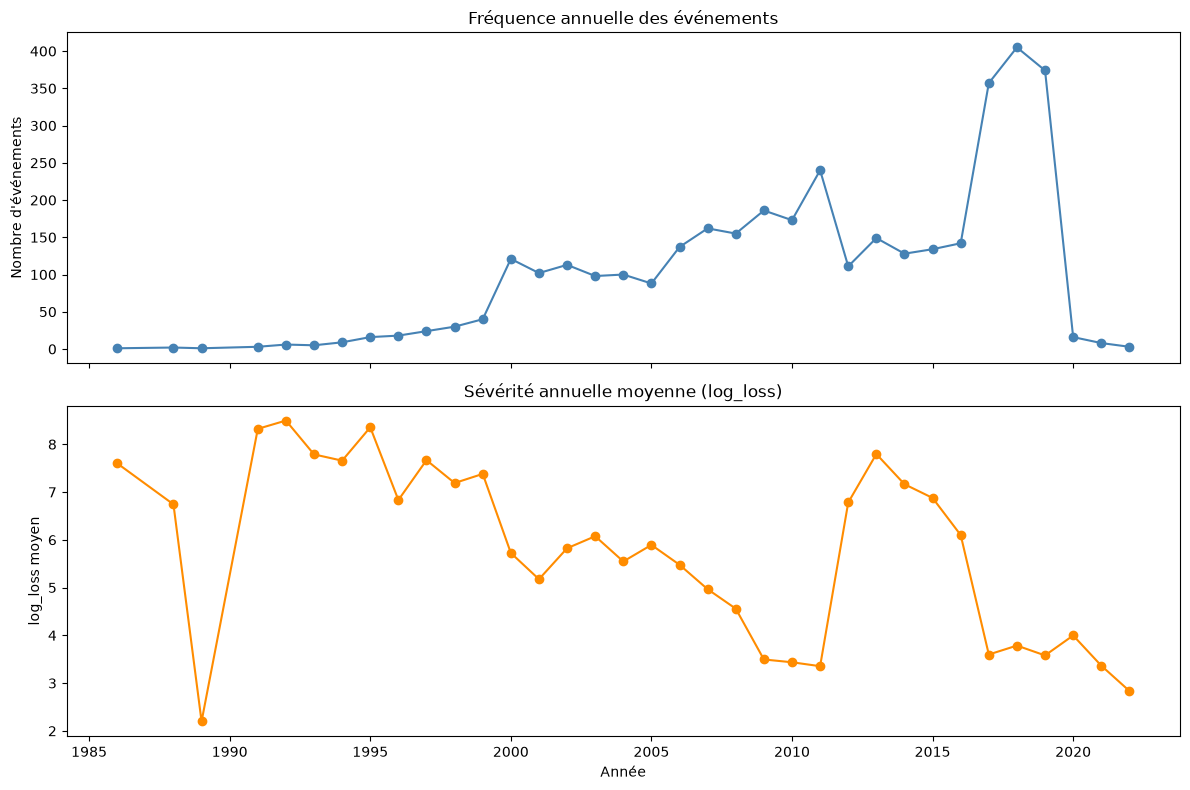

In [26]:
freq_annuelle = df_temps.groupby('Occurrence year').size().sort_index()
severite_annuelle = df_temps.groupby('Occurrence year')['log_loss'].mean().sort_index()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(freq_annuelle.index, freq_annuelle.values, marker='o', color='steelblue')
axes[0].set_title("Fréquence annuelle des événements")
axes[0].set_ylabel("Nombre d'événements")

axes[1].plot(severite_annuelle.index, severite_annuelle.values, marker='o', color='darkorange')
axes[1].set_title("Sévérité annuelle moyenne (log_loss)")
axes[1].set_ylabel("log_loss moyen")
axes[1].set_xlabel("Année")

plt.tight_layout()
plt.show()

In [27]:
def test_adf(serie, nom):
    resultat = adfuller(serie.dropna(), autolag='AIC')
    print(f"--- Test ADF : {nom} ---")
    print(f"Statistique ADF : {resultat[0]:.4f}")
    print(f"p-value         : {resultat[1]:.4f}")
    print(f"Nb lags utilisés: {resultat[2]}")
    print("Valeurs critiques :")
    for cle, valeur in resultat[4].items():
        print(f"   {cle} : {valeur:.4f}")
    if resultat[1] < 0.05:
        print(">> H0 rejetée : série stationnaire au seuil de 5%")
    else:
        print(">> H0 non rejetée : série non stationnaire au seuil de 5% (différenciation à envisager)")
    print()
    return resultat

adf_freq = test_adf(freq_annuelle, "Fréquence annuelle des événements")
adf_sev = test_adf(severite_annuelle, "Sévérité annuelle moyenne (log)")

--- Test ADF : Fréquence annuelle des événements ---
Statistique ADF : -0.4383
p-value         : 0.9035
Nb lags utilisés: 7
Valeurs critiques :
   1% : -3.6996
   5% : -2.9764
   10% : -2.6276
>> H0 non rejetée : série non stationnaire au seuil de 5% (différenciation à envisager)

--- Test ADF : Sévérité annuelle moyenne (log) ---
Statistique ADF : -2.1798
p-value         : 0.2137
Nb lags utilisés: 1
Valeurs critiques :
   1% : -3.6461
   5% : -2.9541
   10% : -2.6160
>> H0 non rejetée : série non stationnaire au seuil de 5% (différenciation à envisager)



### Effet de troncature en fin de période

La base étant construite par voie de presse, un événement récent peut ne pas encore être médiatisé ou judiciarisé au moment de la collecte, ce qui peut sous-représenter artificiellement les toutes dernières années.

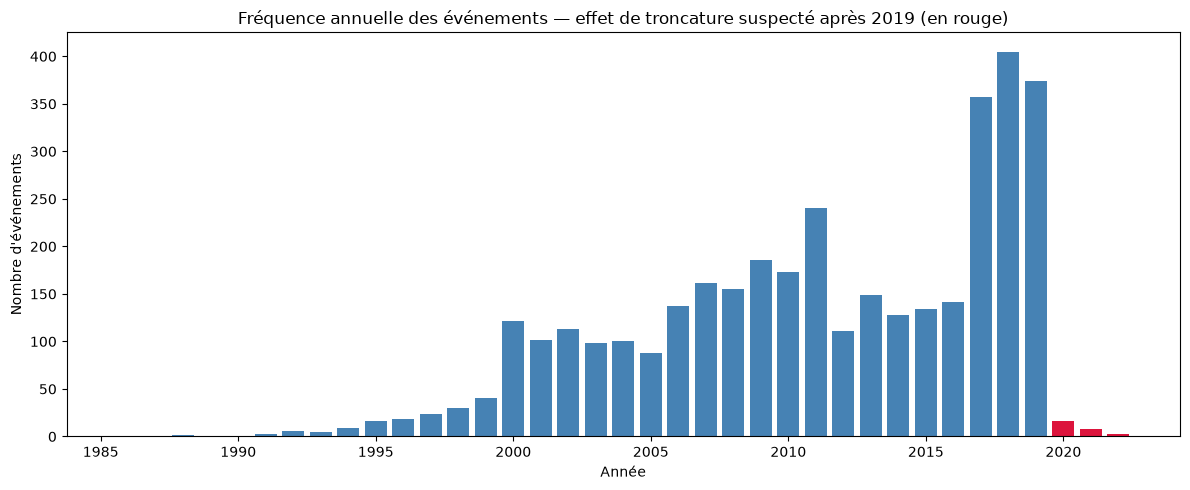

Occurrence year
2015    134
2016    142
2017    357
2018    405
2019    374
2020     16
2021      8
2022      3
dtype: int64


In [28]:
fig, ax = plt.subplots(figsize=(12, 5))
couleurs = ['steelblue' if annee < 2020 else 'crimson' for annee in freq_annuelle.index]
ax.bar(freq_annuelle.index, freq_annuelle.values, color=couleurs)
ax.set_title("Fréquence annuelle des événements — effet de troncature suspecté après 2019 (en rouge)")
ax.set_xlabel("Année")
ax.set_ylabel("Nombre d'événements")
plt.tight_layout()
plt.show()

print(freq_annuelle.tail(8))

La chute brutale de la fréquence à partir de 2020 (405 événements en 2018 contre 3 en 2022) ne traduit vraisemblablement pas une baisse réelle du risque opérationnel, mais un effet de troncature lié au mode de collecte de la base. Ce point devra être pris en compte dans les analyses temporelles et discuté explicitement dans les limites du mémoire.